# Buried-target SAR backscatter vs. soil moisture: two-layer reduced-order simulation

This notebook produces plots: one for each target material (plastic, concrete, metal) at each of S, C, and X band. Each figure overlays clay, loam, and sand for **HH and VV**, with the **−20 dB reference threshold**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Reproducible scenario parameters
C0 = 299_792_458.0
EPS0 = 8.8541878128e-12
MU0 = 4e-7 * np.pi

BANDS_GHZ = {"S": 3.2, "C": 5.3, "X": 9.65}
MOISTURE = np.linspace(0.02, 0.35, 100)  # volumetric moisture fraction (m3/m3)
INCIDENCE_DEG = 30.0
BURIAL_DEPTH_M = 0.20
SLAB_THICKNESS_M = 0.05
RMS_ROUGHNESS_M = 0.010
CORRELATION_LENGTH_M = 0.10
BULK_DENSITY_G_CM3 = 1.60
EFFECTIVE_TARGET_CELL_FACTOR = 0.10  # equivalent normalized-backscatter coupling; sensitivity parameter
THRESHOLD_DB = -20.0

# Texture fractions are illustrative mineral-soil classes, not universal soil definitions.
SOILS = {
    "Clay": {"sand": 0.20, "clay": 0.45},
    "Loam": {"sand": 0.40, "clay": 0.20},
    "Sand": {"sand": 0.90, "clay": 0.03},
}

# Illustrative relative permittivity / conductivity assumptions for target materials.
# Dielectric materials use epsilon = epsilon' - j epsilon''; metal loss is represented via conductivity.
TARGETS = {
    "Plastic": {"eps_real": 2.6, "eps_loss": 0.03, "conductivity_S_m": 0.0},
    "Concrete": {"eps_real": 6.0, "eps_loss": 0.80, "conductivity_S_m": 0.0},
    "Metal": {"eps_real": 1.0, "eps_loss": 0.0, "conductivity_S_m": 1.0e6},
}

print("Bands (GHz):", BANDS_GHZ)
print(f"Burial depth = {BURIAL_DEPTH_M:.2f} m; slab thickness = {SLAB_THICKNESS_M:.2f} m; incidence = {INCIDENCE_DEG:.1f}°")
print(f"Target-cell coupling factor = {EFFECTIVE_TARGET_CELL_FACTOR:.3f}; threshold = {THRESHOLD_DB:.1f} dB")

Bands (GHz): {'S': 3.2, 'C': 5.3, 'X': 9.65}
Burial depth = 0.20 m; slab thickness = 0.05 m; incidence = 30.0°
Target-cell coupling factor = 0.100; threshold = -20.0 dB


In [ ]:
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
})

## 1. Soil dielectric closure

The Dobson-style mixture is used to provide a frequency-dependent complex soil permittivity from texture and moisture. The water permittivity is represented with a single-Debye approximation at 20 °C and a small effective conductivity. This is a transparent engineering closure; it is not a substitute for measured complex permittivity or a fully calibrated Hallikainen coefficient table.

In [3]:
def water_permittivity(f_hz, temperature_C=20.0, conductivity_S_m=0.01):
    """Single-Debye complex relative permittivity, eps = eps' - j eps'' convention."""
    # Approximate 20 C values; weak temperature dependence omitted for reproducibility.
    eps_static = 80.1
    eps_inf = 4.9
    tau = 8.27e-12
    omega = 2 * np.pi * f_hz
    # For exp(+j omega t), the loss term is negative imaginary.
    eps = eps_inf + (eps_static - eps_inf) / (1 + 1j * omega * tau)
    eps -= 1j * conductivity_S_m / (omega * EPS0)
    return eps


def soil_permittivity_dobson(theta_v, f_hz, sand_fraction, clay_fraction, bulk_density_g_cm3=1.60,
                             particle_density_g_cm3=2.66, effective_conductivity_S_m=0.01):
    """Compact Dobson-style texture/moisture/frequency mixture, eps = eps' - j eps''."""
    theta_v = np.asarray(theta_v, dtype=float)
    rho_b = bulk_density_g_cm3
    rho_s = particle_density_g_cm3
    # Dry mineral permittivity (Dobson-style approximation)
    eps_solid = (1.01 + 0.44 * rho_s) ** 2 - 0.062
    alpha_m = 0.65
    beta_real = 1.2748 - 0.519 * sand_fraction - 0.152 * clay_fraction
    beta_imag = 1.33797 - 0.603 * sand_fraction - 0.166 * clay_fraction
    eps_water = water_permittivity(f_hz, conductivity_S_m=effective_conductivity_S_m)
    # Power-law/refractive mixing form. Imaginary part is kept positive as a loss magnitude,
    # then encoded using eps' - j eps''.
    eps_real_mix = (1 + (rho_b / rho_s) * (eps_solid**alpha_m - 1)
                    + theta_v**beta_real * (np.real(eps_water)**alpha_m) - theta_v) ** (1 / alpha_m)
    eps_loss_mix = np.maximum(theta_v**beta_imag * (abs(np.imag(eps_water))**alpha_m), 0.0) ** (1 / alpha_m)
    return eps_real_mix - 1j * eps_loss_mix

# Quick check: show how the assumed soil permittivity changes with moisture at C band.
rows=[]
for soil_name, texture in SOILS.items():
    for mv in [0.05, 0.20, 0.35]:
        e = soil_permittivity_dobson(mv, BANDS_GHZ["C"]*1e9, texture["sand"], texture["clay"])
        rows.append({"Soil": soil_name, "theta_v": mv, "epsilon_real": e.real, "epsilon_loss": -e.imag})
pd.DataFrame(rows)

,Soil,theta_v,epsilon_real,epsilon_loss
0,Clay,0.05,4.346540,0.099551
1,Clay,0.20,10.612025,1.138773
2,Clay,0.35,19.449897,3.045698
3,Loam,0.05,4.691729,0.143340
4,Loam,0.20,11.732220,1.385149
5,Loam,0.35,21.087346,3.460750
6,Sand,0.05,6.814558,0.505082
7,Sand,0.20,17.294419,2.724990
8,Sand,0.35,28.388448,5.380939


## 2. Oh bare-soil surface backscatter and buried-slab response

The 1992 Oh model supplies a surface-background estimate for HH and VV. The target proxy uses Fresnel coefficients for a soil–target–soil slab, the air/soil transmission factor, and two-way attenuation to and from 20 cm depth. For the lossy soil, the field attenuation constant is calculated from complex permittivity; the power round-trip factor is \(\exp[-4alpha d/\cos(	heta_s)]\).

In [4]:
def attenuation_alpha(eps_complex, f_hz):
    """Plane-wave field attenuation constant alpha [Np/m] for eps=eps'-j eps'' loss convention."""
    k0 = 2 * np.pi * f_hz / C0
    er = np.real(eps_complex)
    ei = abs(np.imag(eps_complex))
    return k0 * np.sqrt(np.maximum((np.sqrt(er**2 + ei**2) - er) / 2, 0.0))


def complex_refractive_index(eps):
    # Consistent complex square root; choose branch with non-negative real part.
    n = np.sqrt(eps)
    return np.where(np.real(n) < 0, -n, n)


def fresnel_coefficients(eps1, eps2, theta1_rad, polarization):
    """Complex Fresnel field reflection coefficient for incidence from medium 1 to 2."""
    n1 = complex_refractive_index(eps1)
    n2 = complex_refractive_index(eps2)
    sin_t2 = (n1 / n2) * np.sin(theta1_rad)
    cos_t1 = np.cos(theta1_rad) + 0j
    cos_t2 = np.sqrt(1 - sin_t2**2 + 0j)
    if np.real(cos_t2) < 0:
        cos_t2 = -cos_t2
    pol = polarization.upper()
    if pol == "HH":  # TE / horizontal electric field
        return (n1*cos_t1 - n2*cos_t2) / (n1*cos_t1 + n2*cos_t2)
    if pol == "VV":  # TM / vertical electric field
        return (eps2*cos_t1 - eps1*cos_t2) / (eps2*cos_t1 + eps1*cos_t2)
    raise ValueError("polarization must be HH or VV")


def oh_surface_backscatter(eps_soil, f_hz, incidence_deg, rms_height_m, correlation_length_m):
    """Oh et al. (1992) semi-empirical bare-soil sigma0 for HH and VV, linear units."""
    theta = np.deg2rad(incidence_deg)
    wavelength = C0 / f_hz
    k0 = 2 * np.pi / wavelength
    ks = k0 * rms_height_m
    # Normal-incidence Fresnel power reflectivity Gamma_0
    n_soil = complex_refractive_index(eps_soil)
    gamma0 = abs((1 - n_soil) / (1 + n_soil))**2
    gamma0 = max(float(np.real(gamma0)), 1e-8)
    # Oh 1992 empirical terms. p is clipped to avoid nonphysical numerical excursions.
    q = 0.23 * gamma0**0.53 * (1 - np.exp(-ks))
    p = 1 - (2 * theta / np.pi)**(1 / (3 * gamma0)) * np.exp(-ks)
    p = float(np.clip(np.real(p), 1e-4, 1.0))
    g = 0.7 * (1 - np.exp(-0.65 * (ks**1.8)))
    gamma_h = fresnel_coefficients(1.0+0j, eps_soil, theta, "HH")
    gamma_v = fresnel_coefficients(1.0+0j, eps_soil, theta, "VV")
    sigma_vv = g * np.cos(theta)**3 / np.sqrt(p) * (abs(gamma_v)**2 + abs(gamma_h)**2)
    sigma_hh = p * sigma_vv
    sigma_vh = q * sigma_vv
    return {"HH": max(float(np.real(sigma_hh)), 1e-15), "VV": max(float(np.real(sigma_vv)), 1e-15), "HV": max(float(np.real(sigma_vh)), 1e-15)}


def target_slab_permittivity(target_name, f_hz):
    pars = TARGETS[target_name]
    if pars["conductivity_S_m"] > 0:
        omega = 2 * np.pi * f_hz
        # Conductive medium under eps' - j eps'' convention.
        eps_loss = pars["conductivity_S_m"] / (omega * EPS0)
        return pars["eps_real"] - 1j * eps_loss
    return pars["eps_real"] - 1j * pars["eps_loss"]


def slab_reflection(eps_soil, eps_target, f_hz, theta_soil_rad, polarization, thickness_m):
    """Coherent reflection of a target slab embedded in the same soil on both sides."""
    theta_target_sin = (complex_refractive_index(eps_soil) / complex_refractive_index(eps_target)) * np.sin(theta_soil_rad)
    cos_target = np.sqrt(1 - theta_target_sin**2 + 0j)
    if np.real(cos_target) < 0:
        cos_target = -cos_target
    # Soil -> target and target -> soil Fresnel amplitudes
    r12 = fresnel_coefficients(eps_soil, eps_target, theta_soil_rad, polarization)
    theta_target = np.arcsin(theta_target_sin)
    r23 = fresnel_coefficients(eps_target, eps_soil, theta_target, polarization)
    k0 = 2 * np.pi * f_hz / C0
    phase = np.exp(-2j * k0 * complex_refractive_index(eps_target) * cos_target * thickness_m)
    denom = 1 + r12 * r23 * phase
    if abs(denom) < 1e-12:
        denom += 1e-12
    return (r12 + r23 * phase) / denom


def target_backscatter_proxy(eps_soil, target_name, f_hz, incidence_deg, depth_m, thickness_m,
                             polarization, coupling_factor=EFFECTIVE_TARGET_CELL_FACTOR):
    """Equivalent sigma0 proxy for a buried slab, in linear units; not a full-wave target RCS."""
    theta_air = np.deg2rad(incidence_deg)
    n_soil = complex_refractive_index(eps_soil)
    sin_theta_soil = np.sin(theta_air) / max(float(np.real(n_soil)), 1.0)
    theta_soil = np.arcsin(np.clip(sin_theta_soil, -0.999, 0.999))
    eps_target = target_slab_permittivity(target_name, f_hz)

    # Air-to-soil one-way power transmittance approximation. Loss in soil is accounted separately.
    r_air = fresnel_coefficients(1.0+0j, eps_soil, theta_air, polarization)
    T_air_soil = max(0.0, 1.0 - abs(r_air)**2)
    r_slab = slab_reflection(eps_soil, eps_target, f_hz, theta_soil, polarization, thickness_m)
    alpha = attenuation_alpha(eps_soil, f_hz)
    two_way_power_attenuation = np.exp(-4 * alpha * depth_m / max(np.cos(theta_soil), 1e-6))
    sigma_proxy = coupling_factor * (T_air_soil**2) * (abs(r_slab)**2) * two_way_power_attenuation
    return max(float(np.real(sigma_proxy)), 1e-15)


def db10(x):
    return 10 * np.log10(np.maximum(np.asarray(x), 1e-15))

# Sanity check: roughness normalized wavenumber remains in/near Oh's nominal range.
roughness_rows=[]
for band, f_ghz in BANDS_GHZ.items():
    ks = (2*np.pi*f_ghz*1e9/C0) * RMS_ROUGHNESS_M
    kl = (2*np.pi*f_ghz*1e9/C0) * CORRELATION_LENGTH_M
    roughness_rows.append({"Band": band, "f_GHz": f_ghz, "ks": ks, "kl": kl})
pd.DataFrame(roughness_rows)

,Band,f_GHz,ks,kl
0,S,3.20,0.670670,6.706704
1,C,5.30,1.110798,11.107979
2,X,9.65,2.022490,20.224904


## 3. Run all scenarios

The main figures plot the buried-target proxy so that the −20 dB reference applies to the target-associated return rather than to surface clutter. The CSV also contains the Oh surface-background and non-coherent total columns for separate inspection.

In [6]:
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
})

<>:52: SyntaxWarning: invalid escape sequence '\s'
<>:52: SyntaxWarning: invalid escape sequence '\s'
C:\Users\AMD\AppData\Local\Temp\ipykernel_22020\3978919255.py:52: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel("Buried-target backscatter proxy, $\sigma^0_{target}$ (dB)")


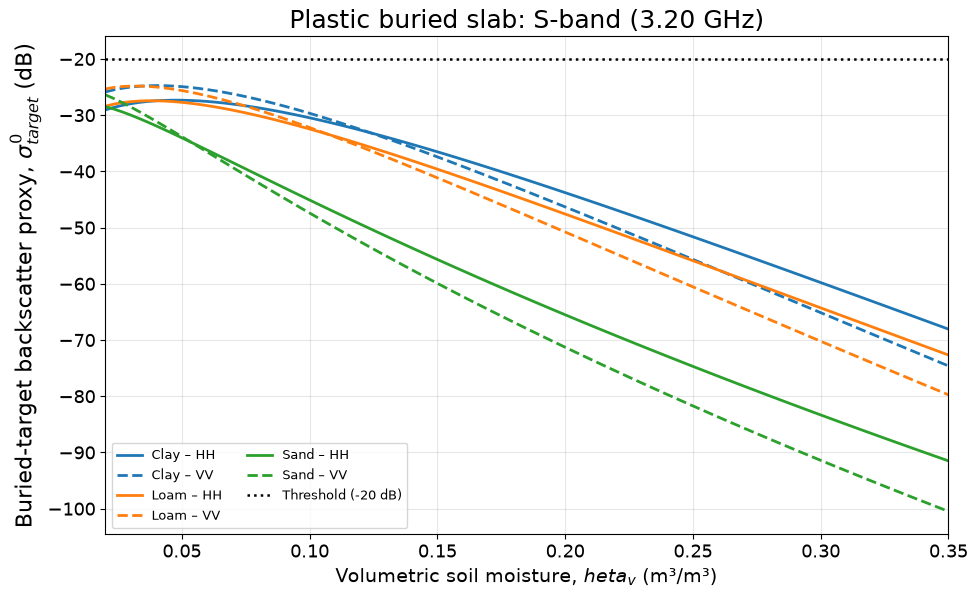

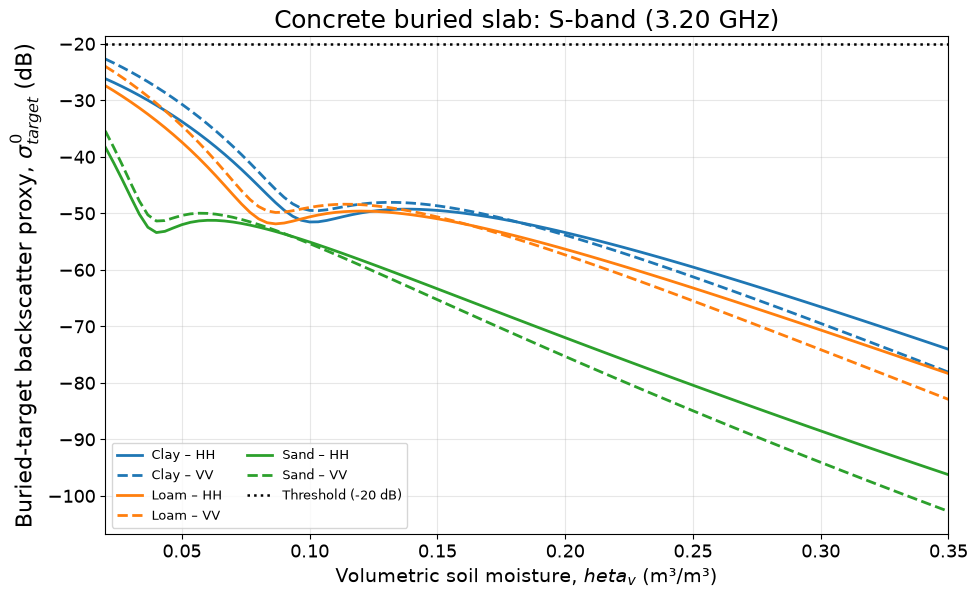

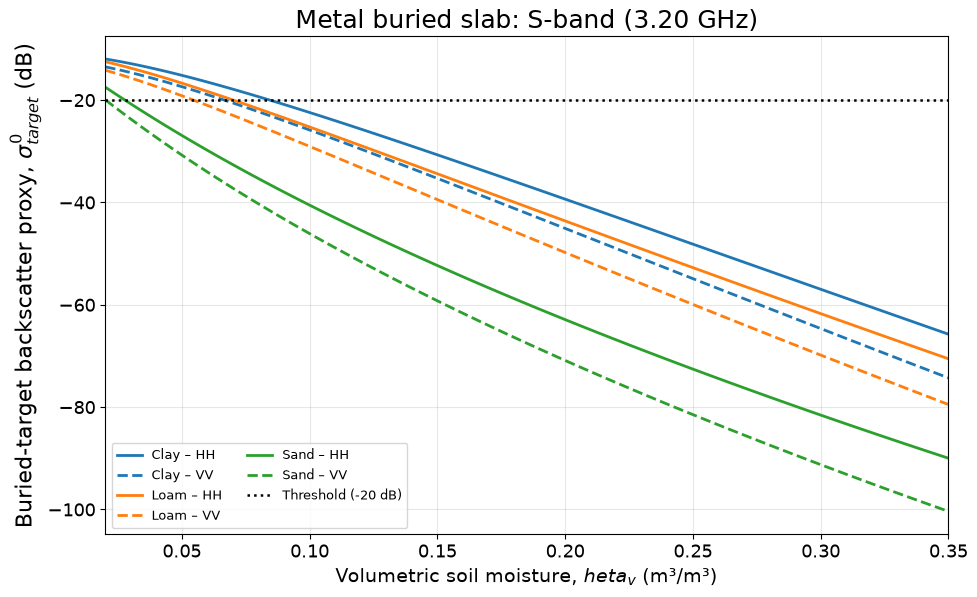

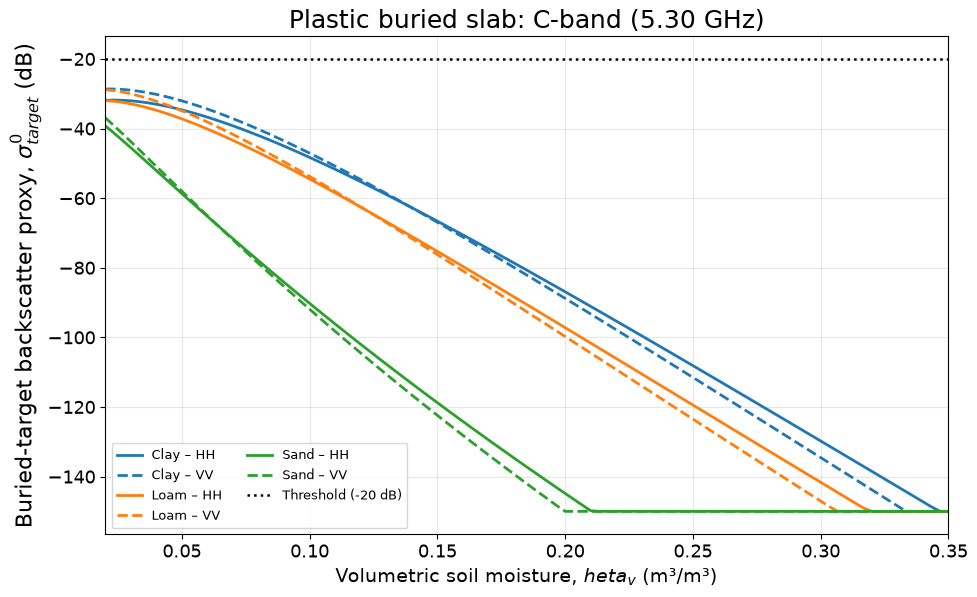

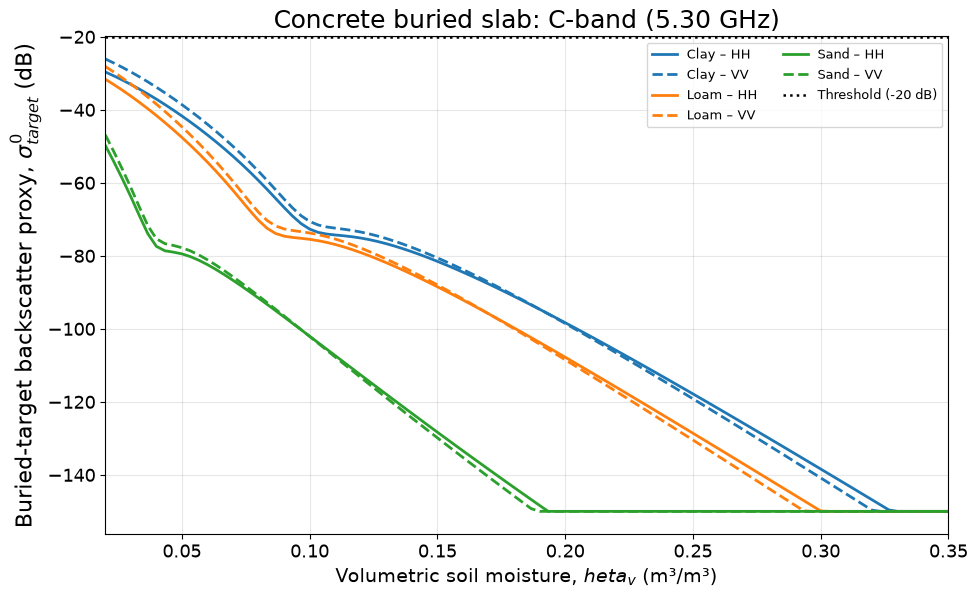

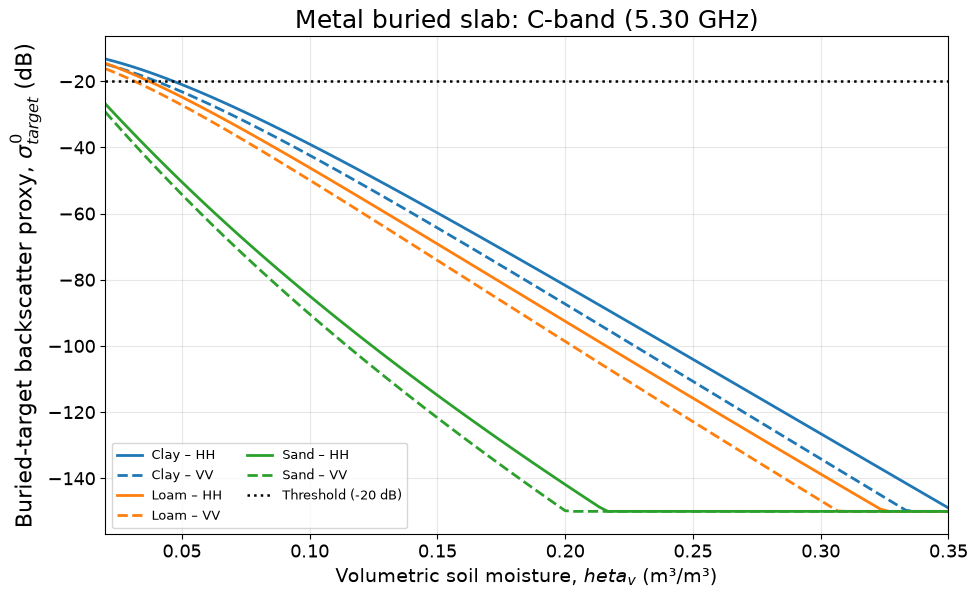

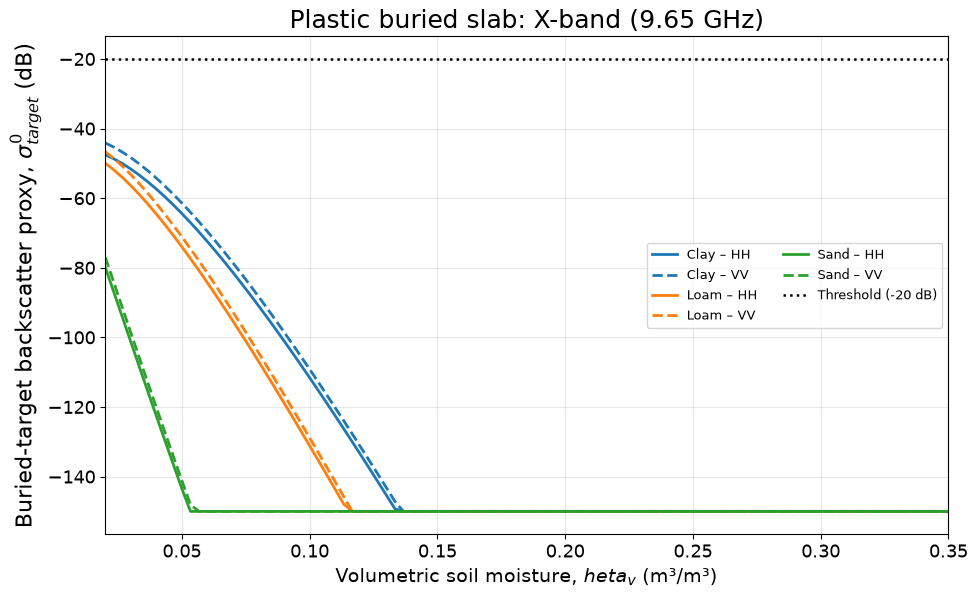

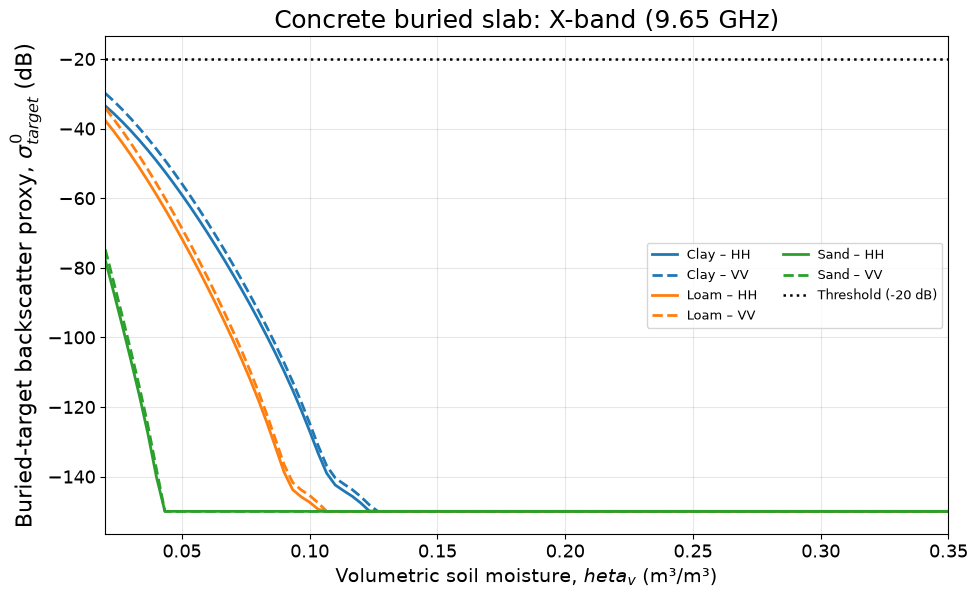

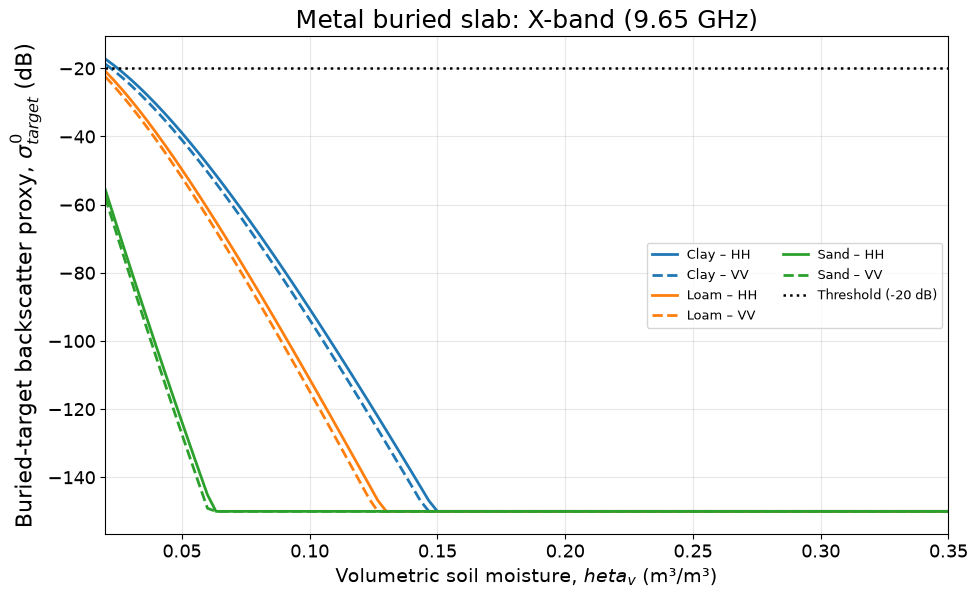

Generated 5,400 moisture/polarization/scenario rows across 9 figure combinations.


In [8]:
def simulate_scenario(band, f_ghz, target_name, soil_name, polarization):
    f_hz = f_ghz * 1e9
    texture = SOILS[soil_name]
    eps = soil_permittivity_dobson(
        MOISTURE, f_hz, texture["sand"], texture["clay"], BULK_DENSITY_G_CM3
    )
    surface = np.array([
        oh_surface_backscatter(e, f_hz, INCIDENCE_DEG, RMS_ROUGHNESS_M, CORRELATION_LENGTH_M)[polarization]
        for e in eps
    ])
    target = np.array([
        target_backscatter_proxy(e, target_name, f_hz, INCIDENCE_DEG, BURIAL_DEPTH_M,
                                 SLAB_THICKNESS_M, polarization)
        for e in eps
    ])
    total = surface + target
    return pd.DataFrame({
        "band": band, "frequency_GHz": f_ghz, "target": target_name, "soil": soil_name,
        "polarization": polarization, "theta_v": MOISTURE,
        "epsilon_real": np.real(eps), "epsilon_loss": -np.imag(eps),
        "surface_sigma0_linear": surface, "target_proxy_linear": target,
        "total_sigma0_linear": total,
        "surface_dB": db10(surface), "target_proxy_dB": db10(target), "total_dB": db10(total),
    })

all_results = []
for band, f_ghz in BANDS_GHZ.items():
    for target_name in TARGETS:
        for soil_name in SOILS:
            for pol in ["HH", "VV"]:
                all_results.append(simulate_scenario(band, f_ghz, target_name, soil_name, pol))
results = pd.concat(all_results, ignore_index=True)

# Nine figures: one target per band. Every figure has 3 soil types x 2 polarizations.
soil_colors = {"Clay": "tab:blue", "Loam": "tab:orange", "Sand": "tab:green"}
pol_styles = {"HH": "-", "VV": "--"}

for band, f_ghz in BANDS_GHZ.items():
    for target_name in TARGETS:
        fig, ax = plt.subplots(figsize=(10, 6.2))
        subset = results[(results["band"] == band) & (results["target"] == target_name)]
        for soil_name in SOILS:
            for pol in ["HH", "VV"]:
                cur = subset[(subset["soil"] == soil_name) & (subset["polarization"] == pol)]
                ax.plot(cur["theta_v"], cur["target_proxy_dB"],
                        color=soil_colors[soil_name], linestyle=pol_styles[pol], linewidth=2,
                        label=f"{soil_name} – {pol}")
        ax.axhline(THRESHOLD_DB, color="black", linestyle=":", linewidth=1.8,
                   label=f"Threshold ({THRESHOLD_DB:.0f} dB)")
        ax.set_title(f"{target_name} buried slab: {band}-band ({f_ghz:.2f} GHz)")
        ax.set_xlabel("Volumetric soil moisture, $\theta_v$ (m³/m³)", fontsize = 14)
        ax.set_ylabel("Buried-target backscatter proxy, $\sigma^0_{target}$ (dB)")
        ax.grid(True, alpha=0.3)
        ax.set_xlim(float(MOISTURE.min()), float(MOISTURE.max()))
        ax.legend(ncol=2, fontsize=9, frameon=True)
        fig.tight_layout()
        # Example: concrete_c.png, metal_x.png, plastic_l.png
        filename = f"{target_name.lower()}_{band.lower()}.png"

        fig.savefig(
            filename,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )
        plt.show()

print(f"Generated {len(results):,} moisture/polarization/scenario rows across 9 figure combinations.")

## 4. Threshold summary and exported data

The table below reports the moisture intervals where the simulated buried-target is at or above −20 dB. These are model outputs under the stated assumptions, not empirical detection probabilities. CSV output is written beside the notebook when the cell runs.

In [5]:
def above_threshold_intervals(x, y_db, threshold_db=THRESHOLD_DB):
    above = np.asarray(y_db) >= threshold_db
    if not np.any(above):
        return "none"
    idx = np.where(above)[0]
    # Group contiguous indices into intervals.
    groups = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
    parts=[]
    for g in groups:
        parts.append(f"{x[g[0]]:.3f}–{x[g[-1]]:.3f}")
    return "; ".join(parts)

summary_rows=[]
for (band, target, soil, pol), group in results.groupby(["band", "target", "soil", "polarization"], sort=False):
    group = group.sort_values("theta_v")
    peak_i = group["target_proxy_dB"].idxmax()
    summary_rows.append({
        "Band": band, "Target": target, "Soil": soil, "Pol": pol,
        "Peak target proxy (dB)": round(float(group.loc[peak_i, "target_proxy_dB"]), 2),
        "Moisture at peak": round(float(group.loc[peak_i, "theta_v"]), 3),
        "Moisture intervals target proxy >= -20 dB": above_threshold_intervals(group["theta_v"].to_numpy(), group["target_proxy_dB"].to_numpy()),
    })
threshold_summary = pd.DataFrame(summary_rows)
display(threshold_summary)

results.to_csv("buried_target_sar_moisture_curves.csv", index=False)
threshold_summary.to_csv("buried_target_sar_threshold_summary.csv", index=False)
print("Wrote buried_target_sar_moisture_curves.csv and buried_target_sar_threshold_summary.csv")

,Band,Target,Soil,Pol,Peak target proxy (dB),Moisture at peak,Moisture intervals target proxy >= -20 dB
0,S,Plastic,Clay,HH,-27.33,0.047,none
1,S,Plastic,Clay,VV,-24.74,0.040,none
2,S,Plastic,Loam,HH,-27.44,0.037,none
3,S,Plastic,Loam,VV,-24.82,0.033,none
4,S,Plastic,Sand,HH,-28.47,0.020,none
5,S,Plastic,Sand,VV,-26.38,0.020,none
6,S,Concrete,Clay,HH,-26.18,0.020,none
7,S,Concrete,Clay,VV,-22.69,0.020,none
8,S,Concrete,Loam,HH,-27.42,0.020,none
9,S,Concrete,Loam,VV,-23.99,0.020,none


Wrote buried_target_sar_moisture_curves.csv and buried_target_sar_threshold_summary.csv


### References

1. Y. Oh, K. Sarabandi, and F. T. Ulaby, “Semi-Empirical Model of the Ensemble-Averaged Differential Mueller Matrix for Microwave Backscattering From Bare Soil Surfaces,” *IEEE Transactions on Geoscience and Remote Sensing*, 40(6), 2002. Its HH/VV surface-scattering context is used as the background model; the later full Mueller-matrix model is not confused with the 1992 compact Oh model.
2. S. Aslani-Katouli, J. Amini, and B. Hosseini, “Tomographic SAR Profiling for Buried Target Detection using Multilayer Physical Modelling,” *Earth Observation and Geomatics Engineering*, 8(2), 2024/2025. Its multilayer propagation, Fresnel transmission, and moisture-dependent attenuation motivate the soil path treatment.
3. G. Tian et al., “The Research on SAR Imaging Technology of Buried Object,” 2017. Its buried-target-under-soil scattering and SAR back-projection context motivate the scenario, while this notebook uses a simpler reduced-order slab proxy rather than KA–BIM full-wave scattering.